# 03 · Modelado y entrenamiento

El entrenamiento histórico ya está realizado. Este notebook inspecciona sus configuraciones, pesos y curvas. Entrenar es opcional y está desactivado para no iniciar 100 épocas por accidente.

In [1]:
from pathlib import Path
import sys, json, csv, hashlib
from html import escape
from IPython.display import display, Markdown, HTML, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/paths.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
def load(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))
def table(rows):
    if not rows:
        return display(Markdown("Sin filas."))
    keys = list(rows[0])
    head = "".join("<th>" + escape(str(k)) + "</th>" for k in keys)
    body = "".join("<tr>" + "".join("<td>" + escape(str(r.get(k, ""))) + "</td>" for k in keys) + "</tr>" for r in rows)
    display(HTML("<table><thead><tr>"+head+"</tr></thead><tbody>"+body+"</tbody></table>"))
print("Raíz del proyecto localizada. Se utilizan evidencias reales del repositorio.")


Raíz del proyecto localizada. Se utilizan evidencias reales del repositorio.


In [2]:
import yaml
names=["yolov9t_baseline","yolov9t_regularizacion","yolov9t_rotacion"]
configs={n:yaml.safe_load((ROOT/"results/training"/n/"args.yaml").read_text(encoding="utf-8")) for n in names}
keys=["epochs","imgsz","batch","seed","optimizer","weight_decay","degrees"]
table([{"experimento":n,**{k:configs[n][k] for k in keys}} for n in names])

experimento,epochs,imgsz,batch,seed,optimizer,weight_decay,degrees
yolov9t_baseline,100,640,16,42,auto,0.0005,0.0
yolov9t_regularizacion,100,640,16,42,auto,0.001,0.0
yolov9t_rotacion,100,640,16,42,auto,0.0005,5.0


## Detector y OCR separados

YOLOv9t entrenado para una clase; el OCR `cct-s-v2-global-model` es preentrenado y no se entrenó localmente. La web usa regularización y la consola tiene por defecto otro backend: no son métricas intercambiables.

In [3]:
arch=load("results/reports/arquitectura_modelos.json")
table([{k:v for k,v in arch["detector"].items() if k!="yaml"}])
manifest=load("models/manifest.json")
weight=ROOT/manifest["web_detector"]["path"]
if weight.is_file():
    assert hashlib.sha256(weight.read_bytes()).hexdigest()==manifest["web_detector"]["sha256"]
    print("Checkpoint web verificado por SHA256.")
else:
    print("Descargar pesos según models/README.md antes de inferencia; no se afirma que estén cargados.")

checkpoint,sha256,parameters_before_fusion,top_level_blocks,parameters_after_fusion
models/best.pt,f2241a4bdb0e2125fcc233b799d5c928fd71c5b068e9bedbc250bc4f7e7843a2,2005603,23,1970979


Checkpoint web verificado por SHA256.


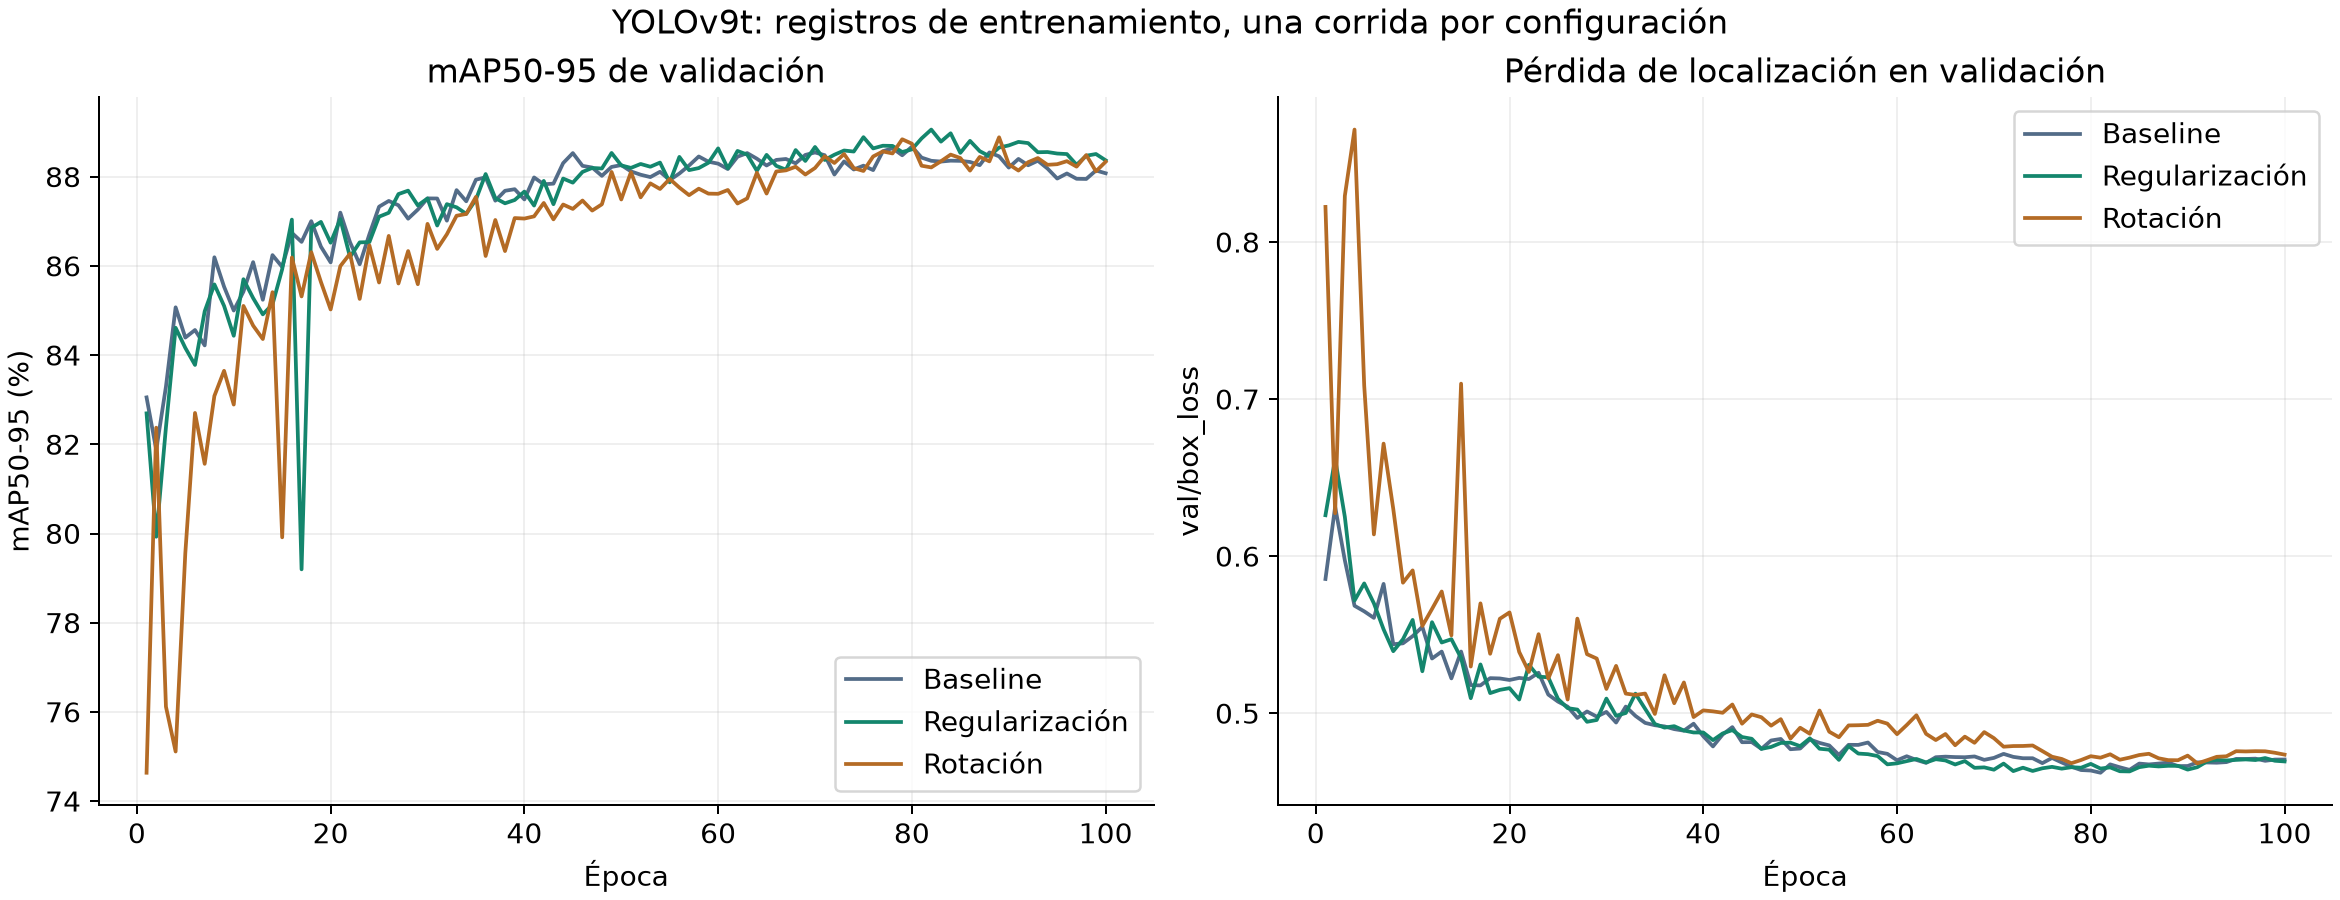

In [4]:
display(Image(filename=str(ROOT/"results/figures/comparacion_entrenamiento.png"),width=1000))

## Reentrenamiento opcional

Requiere dataset local, peso base, CUDA y el entorno de entrenamiento correspondiente. Los scripts impiden sobrescribir nombres existentes. No habilitar sin revisar rutas y presupuesto de ejecución.

In [5]:
RUN_TRAINING=False
if RUN_TRAINING:
    import subprocess
    subprocess.run([sys.executable,"-m","src.entrenar_placas"],cwd=ROOT,check=True)
else:
    print("No se realizó nuevo entrenamiento. Los registros corresponden a las corridas históricas.")

No se realizó nuevo entrenamiento. Los registros corresponden a las corridas históricas.
